<h1><center> Logistic Regression From Scratch

In [161]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [162]:
data = pd.read_csv('Salary.csv', sep='\t')

data.head()

,YearsExperience,Salary,HighSalary
0,1.1,343,0
1,1.3,375,0
2,1.5,381,0
3,2.0,391,0
4,2.2,395,0


In [163]:
data

,YearsExperience,Salary,HighSalary
0,1.1,343,0
1,1.3,375,0
2,1.5,381,0
3,2.0,391,0
4,2.2,395,0
5,3.0,1542,1
6,3.2,1650,1
7,3.7,1545,1
8,4.0,1645,1
9,4.5,3789,1


In [164]:
x_train = data[['YearsExperience', 'Salary']].values
y_train = data['HighSalary'].values

m, n = x_train.shape

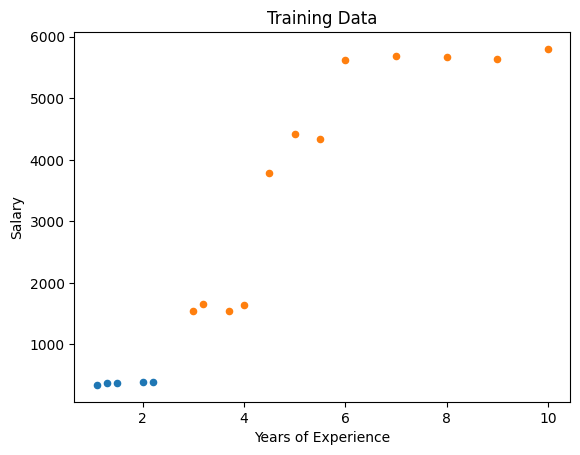

In [165]:
plt.scatter(x_train[y_train == 0, 0], x_train[y_train == 0, 1], color= 'tab:blue', label='Class0', s=20)
plt.scatter(x_train[y_train == 1, 0], x_train[y_train == 1, 1], color= 'tab:orange', label='Class1', s=20)

plt.xlabel('Years of Experience')

plt.ylabel('Salary')
plt.title('Training Data')
plt.show()

In [166]:
def sigmoid(z):
    return 1/ (1+ np.exp(-z))

In [167]:
# First, we create the cost function
def sigmoid_cost_function(x, y, w, b):
    cost_sum = 0
    
    for i in range(m):
        
        f =  np.dot(w, x[i]) + b   # La droite de régression
        z = sigmoid(f)  # La fonction régression logistique
        
        cost_sum += -y[i]*np.log(z) - (1 - y[i])*(np.log(1-z))
        
    return (1/m)* cost_sum
    

In [168]:
# Second, we create a gradient descent function to calculate derivatives of loss by w and b

def gradient_descent(x, y, w, b):
    dj_dw= np.zeros(n)
    dj_db = 0
    
    for i in range(m):  
        f = np.dot(w, x[i]) + b
        z = sigmoid(f)
        
        
        dj_db += (z - y[i])
        
        for j in range(n):
            dj_dw += (z - y[i]) * x[i,j]
            
        
    dj_dw = (1/m)* dj_dw
    dj_db = (1/m) * dj_db
    
    return dj_dw, dj_db
        

In [169]:
# Finally, we create a gradient descent function to comute and update w and b

def gradient_descent_function(x, y, alpha, iteration):
    w = np.zeros(n)
    b = 0
    
    for i in range(iteration):
        dj_dw, dj_db = gradient_descent(x, y, w, b)
        
        w = w - alpha * dj_dw
        
        b = b - alpha * dj_db
        
        if (i% 10 == 0):
            print(f" Iteration {i}: Cost: {sigmoid_cost_function(x, y, w, b)}")
        
    return w, b


In [170]:
"""# run the code
alpha = 0.01
iteration = 1000

final_w, final_b = gradient_descent_function(x_train, y_train, alpha, iteration)
"""

'# run the code\nalpha = 0.01\niteration = 1000\n\nfinal_w, final_b = gradient_descent_function(x_train, y_train, alpha, iteration)\n'

In [171]:
def predict(X, w, b):
    preds = np.zeros(m)

    for i in range(m):
        z = np.dot(w, X[i]) + b
        g = sigmoid(z)

        preds[i] = 1 if g >= 0.5 else 0
    
    return preds

In [172]:
learning_rate = 0.01
iterations = 10000

final_w, final_b = gradient_descent_function(x_train, y_train, learning_rate, iterations)

predictions = predict(x_train, final_w, final_b)
accuracy = np.mean(predictions == y_train) * 100
print(f"training accuracy: {accuracy:.2f}%")

C:\Users\hp\AppData\Local\Temp\ipykernel_13204\558858465.py:10: RuntimeWarning: divide by zero encountered in log
  cost_sum += -y[i]*np.log(z) - (1 - y[i])*(np.log(1-z))
C:\Users\hp\AppData\Local\Temp\ipykernel_13204\558858465.py:10: RuntimeWarning: invalid value encountered in scalar multiply
  cost_sum += -y[i]*np.log(z) - (1 - y[i])*(np.log(1-z))
C:\Users\hp\AppData\Local\Temp\ipykernel_13204\154366226.py:2: RuntimeWarning: overflow encountered in exp
  return 1/ (1+ np.exp(-z))


 Iteration 0: Cost: nan
 Iteration 10: Cost: nan
 Iteration 20: Cost: nan
 Iteration 30: Cost: nan
 Iteration 40: Cost: nan
 Iteration 50: Cost: nan
 Iteration 60: Cost: nan
 Iteration 70: Cost: nan
 Iteration 80: Cost: nan
 Iteration 90: Cost: nan
 Iteration 100: Cost: nan
 Iteration 110: Cost: nan
 Iteration 120: Cost: nan
 Iteration 130: Cost: nan
 Iteration 140: Cost: nan
 Iteration 150: Cost: nan
 Iteration 160: Cost: nan
 Iteration 170: Cost: nan
 Iteration 180: Cost: nan
 Iteration 190: Cost: nan
 Iteration 200: Cost: nan
 Iteration 210: Cost: nan
 Iteration 220: Cost: nan
 Iteration 230: Cost: nan
 Iteration 240: Cost: nan
 Iteration 250: Cost: nan
 Iteration 260: Cost: nan
 Iteration 270: Cost: nan
 Iteration 280: Cost: nan
 Iteration 290: Cost: nan
 Iteration 300: Cost: nan
 Iteration 310: Cost: nan
 Iteration 320: Cost: nan
 Iteration 330: Cost: nan
 Iteration 340: Cost: nan
 Iteration 350: Cost: nan
 Iteration 360: Cost: nan
 Iteration 370: Cost: nan
 Iteration 380: Cost: n

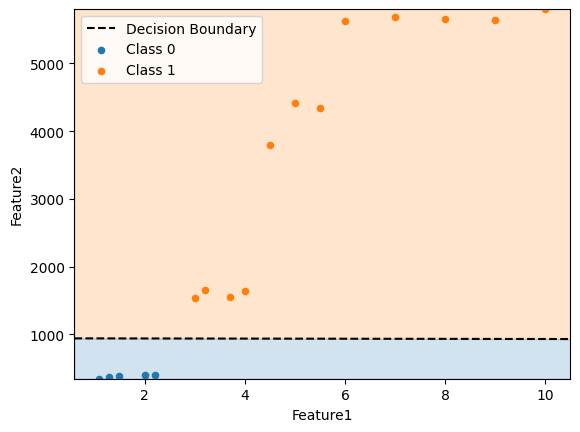

In [173]:
m = -final_w[0] / final_w[1]
c = -final_b / final_w[1]

xmin, xmax = x_train[:, 0].min() - 0.5, x_train[:, 0].max() + 0.5
ymin, ymax = x_train[:, 1].min() - 0.5, x_train[:, 1].max() + 0.5
xd = np.array([xmin, xmax])
yd = m * xd + c

plt.plot(xd, yd, 'k', ls='--', label='Decision Boundary')
plt.fill_between(xd, yd, ymin, color='tab:blue', alpha=0.2)
plt.fill_between(xd, yd, ymax, color='tab:orange', alpha=0.2)

plt.scatter(x_train[y_train == 0, 0], x_train[y_train == 0, 1], color='tab:blue', label='Class 0', s=20)
plt.scatter(x_train[y_train == 1, 0], x_train[y_train == 1, 1], color='tab:orange', label='Class 1', s=20)
plt.legend()
plt.xlabel('Feature1')
plt.ylabel('Feature2')
plt.xlim(xmin, xmax)
plt.ylim(ymin, ymax)
plt.show()